In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from technical import technical_init, summary
from sentiment import sentiment_init, Sentiment_result
from datetime import datetime
from stock_monitoring.evaluation import save_model_evaluation
from stock_monitoring.monitoring import monitor_investments, get_connection
import yfinance as yf
import pandas as pd
import sqlite3
import pickle

d:\predict_volatility\Volatility_predictor\volatile_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
with open("model/model.pkl", "rb") as file:
    model = pickle.load(file)

class MarketState(TypedDict):
    ticker: str
    verdict: summary
    volatility: int
    sentiment: Sentiment_result
    human_decsion: Literal["Hold", "Buy", "Sold"]

class EvaluationState(TypedDict, total=False):
    status: str
    evaluation_count: int

In [3]:
def human_decision_node(state: MarketState):
    try:
        ticker = state["ticker"].upper()
        decision = input("Enter your decision in (Hold, Buy, Sell) ").strip().upper()

        if decision not in ("HOLD", "BUY", "SELL"):
            raise ValueError("choose from the give option")

        if decision == "BUY":
            history = yf.Ticker(ticker).history(period="5d")

            if history.empty or history["Close"].dropna().empty:
                raise ValueError(f"No stock price data available for {ticker}")

            price = float(history["Close"].dropna().iloc[-1])
            reason = input("Enter your reason to BUY: ")

            conn = sqlite3.connect("investments.db")

            conn.execute("""
                INSERT INTO investments
                (ticker, decision, entry_price, entry_date, reasoning)
                VALUES (?, ?, ?, ?, ?)
            """, (
                ticker,
                decision,
                price,
                datetime.now().isoformat(),
                reason
            ))

            conn.commit()
            conn.close()
            
        return {"decision": decision}

    except ValueError as e:
        print(e)

    except ConnectionError as e:
        print(f"cannot connect to the database")

In [4]:
def collection(state: MarketState):
    ticker = input("Enter the Stock")
    results = yf.Search(ticker, max_results=10)
    for stocks in results.quotes:
        stock = stocks["symbol"]
        break
    return {"ticker": stock}

def technode(state: MarketState):
    ticker = state["ticker"]
    result = technical_init(ticker)
    return {"verdict": result}

def sentimentnode(state: MarketState):
    ticker = state["ticker"]
    result = sentiment_init(ticker)
    return {"sentiment": result}

def output(state: MarketState):
    ans = state["verdict"].Position
    print(ans)
    return {"result": ans}

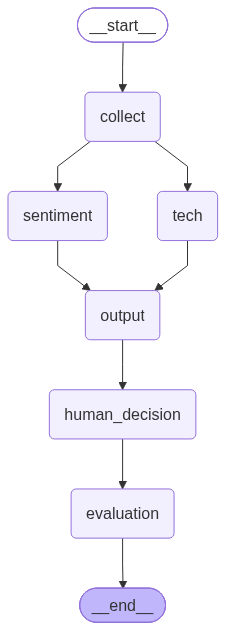

In [5]:
graph = StateGraph(MarketState)

graph.add_node("tech", technode)
graph.add_node("sentiment", sentimentnode)
graph.add_node("collect", collection)
graph.add_node("output", output)
graph.add_node("human_decision", human_decision_node)
graph.add_node("evaluation", save_model_evaluation)

graph.add_edge(START, "collect")
graph.add_edge("collect", "sentiment")
graph.add_edge("collect", "tech")

graph.add_edge("tech", "output")
graph.add_edge("sentiment", "output")
graph.add_edge("output", "human_decision")
graph.add_edge("human_decision", "evaluation")
graph.add_edge("human_decision", END)

graph.compile()

In [2]:
workflow = graph.compile()

NameError: name 'graph' is not defined

In [12]:
initial_state = {}
result = workflow.invoke(initial_state)

UnboundLocalError: cannot access local variable 'stock' where it is not associated with a value

In [ ]:
print(workflow.get_state_history)

<bound method Pregel.get_state_history of <langgraph.graph.state.CompiledStateGraph object at 0x000002177F9DB610>>


In [3]:
def monitoring(state: EvaluationState):
    monitor_investments()
    return {"status": "monitoring_completed"}

def evaluation_node(state: EvaluationState):
    with get_connection() as conn:
        rows = conn.execute("""
            SELECT m.id, m.entry_price, p.price
            FROM investments AS m
            JOIN (
                SELECT investment_id, MAX(id) AS latest_id
                FROM price_history
                GROUP BY investment_id
            ) AS latest
                ON latest.investment_id = m.id
            JOIN price_history AS p
                ON p.id = latest.latest_id
        """).fetchall()

    for investment_id, entry_price, evaluation_price in rows:
        save_model_evaluation(
            investment_id=investment_id,
            entry_price=entry_price,
            evaluation_price=evaluation_price,
            # evaluation_period_days=14,
        )

    return {"evaluation_count": len(rows)}

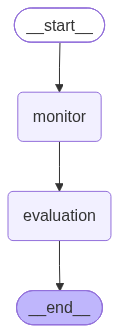

In [4]:
graph2 = StateGraph(EvaluationState)

graph2.add_node("monitor", monitoring)
graph2.add_node("evaluation", evaluation_node)

graph2.add_edge(START, "monitor")
graph2.add_edge("monitor", "evaluation")
graph2.add_edge("evaluation", END)

graph2.compile()

In [5]:
workflow2 = graph2.compile()

In [6]:
result = workflow2.invoke({})
print("Results from the analysis", result)

RELIANCE.NS: Price=1189.60, Since entry=2.57%, Since previous check=-0.11755032863664987, Review required=False
TATASTEEL.NS: Price=170.73, Since entry=-2.50%, Since previous check=-0.1578972353572734, Review required=False
Actual return: 2.57%
Volatility MAE: None
Technical signal correct: None
Actual return: -2.50%
Volatility MAE: None
Technical signal correct: None
Results from the analysis {'status': 'monitoring_completed', 'evaluation_count': 2}


In [ ]:
conn = sqlite3.connect("investments.db")
output1 = conn.execute(
    """
        Select id, entry_date, entry_price, decision, reasoning
        from investments
    """
)

output2 = conn.execute(
    """
        Select *
        from price_history
        order by id  desc
    """
)

In [ ]:
print(output1)

In [ ]:
rows = output1.fetchall()

for row in rows:
    print(row)

(1, '2026-10-12T11:53:22.669853', 1159.800048828125, 'BUY', 'BUY')
(2, '2026-10-19T12:05:10.778846', 175.11000061035156, 'BUY', 'It seems benificial in long tern')


In [ ]:
rows2 = output2.fetchall()
for row in rows2:
    print(row)